# Auditing a care-management risk score

## Section 4 — Investigate what the score tracks

We compare realized medical cost in two ways:

1. within similar narrow commercial-risk ranges; and
2. within the same recorded active chronic-condition count.



## START/RESTART HERE

Before Task 1, run every setup code cell below in order. Each setup cell is
labeled `# RUN THIS CELL FIRST`; continue until you reach **Task 1**.

The setup cells import packages and load the data.


In [1]:
# RUN THIS CELL FIRST
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")
RACE_STYLES = {
    "black": {"color": "#6A3D9A", "linestyle": "--", "marker": "o"},
    "white": {"color": "#E69F00", "linestyle": "-", "marker": "s"},
}


In [2]:
# RUN THIS CELL FIRST
DATA_COMMIT = "daceb25bba00e65d7b05882f049e229a8bedb60c"
DATA_URL = (
    "https://gitlab.com/labsysmed/dissecting-bias/-/raw/"
    f"{DATA_COMMIT}/data/data_new.csv"
)
LOCAL_DATA_PATH = Path("data_new.csv")


def load_data(required_columns):
    """Load the course data from a local copy or the pinned public URL."""
    source = LOCAL_DATA_PATH if LOCAL_DATA_PATH.is_file() else DATA_URL
    data = pd.read_csv(source)

    missing_columns = sorted(set(required_columns) - set(data.columns))
    if missing_columns:
        raise ValueError(f"Missing required columns: {missing_columns}")

    return data


In [3]:
# RUN THIS CELL FIRST
section_4_columns = ["risk_score_t", "cost_t", "gagne_sum_t", "race"]
df = load_data(section_4_columns)


## Variables used in this section

Each observation represents one patient observed in one year.

- `risk_score_t`: the existing commercial score for year t. Larger values rank
  a patient as higher commercial risk.
- `cost_t`: total realized medical cost in year t, measured in dollars.
- `gagne_sum_t`: the number of active chronic conditions recorded in year t.
  It is a recorded health-status proxy, not a complete measure of health need.
- `race`: the self-reported audit group, `black` or `white`.

All percentiles and score ranges below are pooled across race so the two groups
are compared on the same commercial-score scale.


## Task 1 — Compare future cost within narrow commercial-risk ranges

### Provided score-range setup from Section 3

Tasks 1A–1D were completed in Section 3. The complete code below recreates
the pooled commercial-risk percentiles and 100 narrow score ranges while
retaining `cost_t` for this section. Run the provided cell, then begin your
work at Task 1E.


In [4]:
# PROVIDED: score-range setup completed in Section 3
audit = df.loc[:, section_4_columns].copy()

audit["risk_percentile"] = (
    audit["risk_score_t"].rank(method="average", pct=True) * 100
)

stable_rank = audit["risk_score_t"].rank(method="first")
audit["risk_bin"] = (
    pd.qcut(stable_rank, q=100, labels=False) + 1
)

bin_sizes = audit["risk_bin"].value_counts()
number_of_bins = audit["risk_bin"].nunique()
smallest_bin = bin_sizes.min()
largest_bin = bin_sizes.max()

number_of_bins, smallest_bin, largest_bin


(100, 487, 488)

### 1E — Build `cost_by_risk`

Create a pandas DataFrame named `cost_by_risk`.
- Each group summary should describe the patients that share one `risk_bin` and one `race`; it should not represent an individual patient.
- Both races occur in all 100 bins, so the finished DataFrame should have 200 rows and these five columns:
  - `risk_bin`: the score-range number;
  - `race`: the audit group;
  - `risk_percentile`: the arithmetic mean pooled percentile in that group;
  - `mean_cost`: the arithmetic mean `cost_t`, in dollars, in that group; and
  - `rows`: the number of patients contributing to that group summary.


**Hint:**
Feel free to use the template below. Replace the three `...` placeholders with the required calculations, then convert `cost_by_risk_rows` to a DataFrame.


In [5]:
cost_by_risk_rows = []

for bin_number in range(1, 101):
    for race_name in ["black", "white"]:
        in_group = (
            (audit["risk_bin"] == bin_number)
            & (audit["race"] == race_name)
        )
        group_rows = audit.loc[in_group]

        cost_by_risk_rows.append(
            {
                "risk_bin": bin_number,
                "race": race_name,
                "risk_percentile": group_rows["risk_percentile"].mean(),
                "mean_cost": group_rows["cost_t"].mean(),
                "rows": len(group_rows),
            }
        )

cost_by_risk = pd.DataFrame(cost_by_risk_rows)
cost_by_risk.head()


,risk_bin,race,risk_percentile,mean_cost,rows
0,1,black,0.553753,1033.333333,63
1,1,white,0.535576,905.176471,425
2,2,black,1.519917,1365.079365,63
3,2,white,1.456683,2959.764706,425
4,3,black,2.528770,1271.428571,63


### 1F — Sort and check `cost_by_risk`

Sort `cost_by_risk` first by `race` and then by `risk_percentile`. Confirm that
it has shape `(200, 5)` and that its `rows` column sums to all 48,784 patients. Display its first five observations.


In [6]:
cost_by_risk = cost_by_risk.sort_values(
    ["race", "risk_percentile"]
)

print("Shape:", cost_by_risk.shape)
print("Patients summarized:", cost_by_risk["rows"].sum())
cost_by_risk.head()


Shape: (200, 5)
Patients summarized: 48784


,risk_bin,race,risk_percentile,mean_cost,rows
0,1,black,0.553753,1033.333333,63
2,2,black,1.519917,1365.079365,63
4,3,black,2.528770,1271.428571,63
6,4,black,3.456337,2127.868852,61
8,5,black,4.544282,1400.000000,68


### 1G — Plot the comparison

The code cell immediately below is complete plotting code provided by the instructor.
Run it as is without editing after constructing and sorting `cost_by_risk`.

The horizontal axis is mean pooled `risk_percentile`; the vertical axis is `mean_cost`. The vertical axis uses a logarithmic display scale because the group means span a wide range.

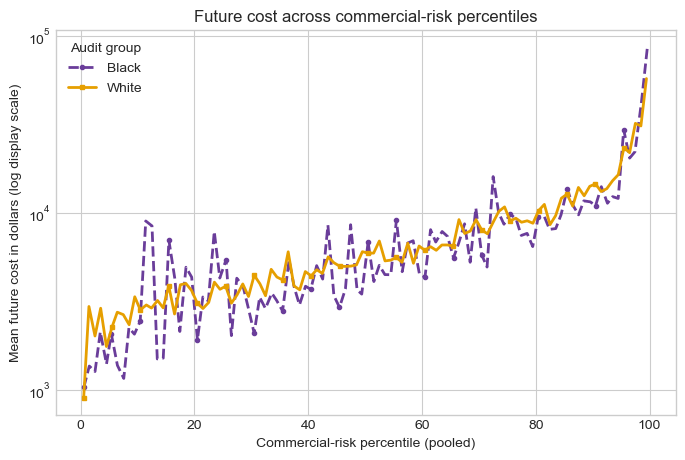

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))

for race, style in RACE_STYLES.items():
    plot_data = cost_by_risk.loc[cost_by_risk["race"] == race]
    ax.plot(
        plot_data["risk_percentile"],
        plot_data["mean_cost"],
        label=race.title(),
        linewidth=2,
        markersize=3,
        markevery=5,
        **style,
    )

ax.set_yscale("log")
ax.set(
    xlabel="Commercial-risk percentile (pooled)",
    ylabel="Mean future cost in dollars (log display scale)",
    title="Future cost across commercial-risk percentiles",
)
ax.legend(title="Audit group")
plt.show()


**Read the figure:** Compare the vertical positions of the Black
series and White series across the different commercial risk scores.
Is there any systematic difference between the two groups?

**Your observation:** [Write one or two sentences here.]


**Solution:** Both groups' mean costs rise with commercial-risk percentile, and the curves broadly track each other. The Black mean is lower in many bins, but the gap fluctuates and sometimes reverses, so the figure does not show a uniform race gap at a given score.


## Task 2 — Compare future cost at the same recorded condition count

### 2A — Pool high condition counts and count patients

**Goal:** Group patients by how many active chronic conditions were recorded for them (`gagne_sum_t`), and count how many Black and White patients fall in each group.

**Why pool 7+?** Very few patients have 7 or more recorded conditions, so all counts of 7 or more are combined into one group, stored as the value 7. In the table and the plot, 7 means "7 or more." This gives eight groups: 0, 1, 2, 3, 4, 5, 6, and 7+.

**Your task:** Replace the two `...` placeholders in the template code cell below:

- `black_rows`: the number of patients in `audit` that are in this group **and**
  have `race` equal to `"black"`; and
- `white_rows`: the same count for `"white"`.

**Hint:** Combine `at_level` with a race condition using `&`. Summing a
Boolean Series counts its `True` values.

**Advice:**

Practice asking google or LLM to help you understand the code if there are anything unclear about the code.

You can also try running a part of the code to see what it does.


In [8]:
audit["condition_group"] = audit["gagne_sum_t"].clip(upper=7)
condition_levels = sorted(audit["condition_group"].unique().tolist())
condition_count_rows = []

for condition_level in condition_levels:
    at_level = audit["condition_group"] == condition_level

    black_rows = int(
        (at_level & (audit["race"] == "black")).sum()
    )
    white_rows = int(
        (at_level & (audit["race"] == "white")).sum()
    )

    condition_count_rows.append(
        {
            "condition_group": condition_level,
            "black": black_rows,
            "white": white_rows,
        }
    )

condition_counts = pd.DataFrame(condition_count_rows).set_index("condition_group")
condition_counts.columns.name = "race"
condition_counts


race,black,white
condition_group,,
0,1752,20459
1,1294,9855
2,860,5410
3,572,3093
4,344,1730
5,253,986
6,156,616
7,351,1053


### 2B — Build `cost_by_conditions`

**Goal:** For each combination of condition group and race, compute the average medical cost. This lets you compare the cost of Black and White patients who have the **same** number of recorded chronic conditions.

**What one summary observation represents.** Each group summary in `cost_by_conditions` summarizes patients.
For example, the group summary with `condition_group == 3` and `race == "black"` summarizes all Black patients with exactly 3 recorded conditions.

**Expected size.** There are 8 condition groups and 2 races, so `cost_by_conditions` should have 8 × 2 = **16 rows** and these four columns:

| Column | What it contains |
|---|---|
| `condition_group` | The recorded condition count, 0 to 7, where 7 means 7 or more |
| `race` | `"black"` or `"white"` |
| `mean_cost` | The **mean** of `cost_t`, in dollars, for the patients in this group |
| `rows` | The **number** of patients in this group |

**Your task:** Replace the two `...` placeholders with values computed from
`group_rows`:

- `"mean_cost"`: the mean of the `cost_t` column; and
- `"rows"`: the number of patients in `group_rows`.

**Check:** The `rows` values should match the counts in `condition_counts`
from 2A.


In [9]:
cost_by_condition_rows = []

for condition_level in condition_levels:
    for race_name in ["black", "white"]:
        in_group = (
            (audit["condition_group"] == condition_level)
            & (audit["race"] == race_name)
        )
        group_rows = audit.loc[in_group]

        cost_by_condition_rows.append(
            {
                "condition_group": condition_level,
                "race": race_name,
                "mean_cost": group_rows["cost_t"].mean(),
                "rows": len(group_rows),
            }
        )

cost_by_conditions = pd.DataFrame(cost_by_condition_rows)
cost_by_conditions.head()


,condition_group,race,mean_cost,rows
0,0,black,3309.931507,1752
1,0,white,4372.520651,20459
2,1,black,5242.040185,1294
3,1,white,6440.395738,9855
4,2,black,7176.976744,860


### 2C — Sort and check `cost_by_conditions`

**Goal:** Put `cost_by_conditions` in the order the plot in 2D needs, and
check that no group summaries were lost along the way.

**Your task:** In the empty code cell below:

1. Sort `cost_by_conditions` first by `race` and then by `condition_group`,
   and save the result back to `cost_by_conditions`. The plot connects points
   in the order the group summaries appear, so without this step the lines will zigzag.
2. Confirm that its shape is `(16, 4)`.
3. Confirm that the `rows` column adds up to 48,784, the total number of patients in `audit`. This shows that every patient is counted in exactly one group.
4. Display the whole table (all 16 rows).


In [10]:
cost_by_conditions = cost_by_conditions.sort_values(
    ["race", "condition_group"]
)

print("Shape:", cost_by_conditions.shape)
print(
    "Patients summarized:",
    cost_by_conditions["rows"].sum(),
)
cost_by_conditions


Shape: (16, 4)
Patients summarized: 48784


,condition_group,race,mean_cost,rows
0,0,black,3309.931507,1752
2,1,black,5242.040185,1294
4,2,black,7176.976744,860
6,3,black,10621.153846,572
8,4,black,11261.046512,344
10,5,black,15723.715415,253
12,6,black,21571.153846,156
14,7,black,44218.233618,351
1,0,white,4372.520651,20459
3,1,white,6440.395738,9855


### 2D — Plot the comparison

**Goal:** Check whether Black and White patients who are equally sick, as
measured by the number of recorded chronic conditions, generate similar
medical costs.

**What the plot shows.** The code cell below draws one line per race from
`cost_by_conditions`:

- horizontal axis: `condition_group` (0 to 6, with the last point labeled
  7+);
- vertical axis: `mean_cost`, shown on a logarithmic scale because the averages
  range from small to very large; and
- each point summarizes patients in one condition-count group and racial group from 2B.

**Your task:**

1. Make sure you have completed 2B (building the table) and 2C (sorting it).
   Otherwise the plot will be wrong or the cell will fail.
2. Run the code cell below. It is complete plotting code provided by the
   instructor, so **do not edit it**.
3. Use the figure to answer the **Read the figure** question that follows.


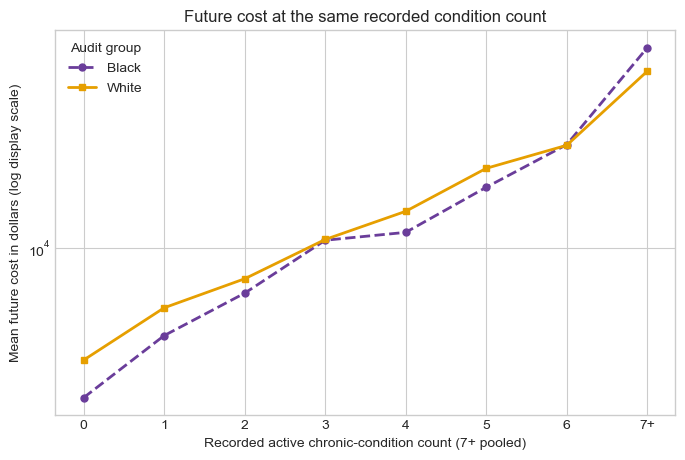

In [11]:
fig, ax = plt.subplots(figsize=(8, 5))

for race, style in RACE_STYLES.items():
    plot_data = cost_by_conditions.loc[cost_by_conditions["race"] == race]
    ax.plot(
        plot_data["condition_group"],
        plot_data["mean_cost"],
        label=race.title(),
        linewidth=2,
        markersize=5,
        **style,
    )

ax.set_yscale("log")
ax.set_xticks(range(8), ["0", "1", "2", "3", "4", "5", "6", "7+"])
ax.set(
    xlabel="Recorded active chronic-condition count (7+ pooled)",
    ylabel="Mean future cost in dollars (log display scale)",
    title="Future cost at the same recorded condition count",
)
ax.legend(title="Audit group")
plt.show()


**Read the figure:** At the same supported condition count, compare the
dashed-circle Black series with the solid-square White series. Describe the
broad pattern.


**Solution:** Mean cost generally rises with recorded condition count, and Black patients have lower mean cost than White patients in groups 0–5 (with almost no difference at 3). The groups have nearly equal mean cost at 6 conditions, while the Black mean is higher in the pooled 7+ group.
